# 19 — Policy Ranking Stability Analysis Across History Conditions
**Project:** Causal-History Dependence in Robot Policy Recovery  
**Phase:** 6 (Pre-Registered Pilot Recovery Experiment)  
**Status:** `Pre-registered pilot` / `Verified`  
**Disclaimer:** Pre-registered pilot analysis — exploratory, not confirmatory. Official benchmark experiments remain paused pending explicit user approval.

This notebook evaluates whether the relative ranking of robot policies changes when evaluated under full execution history (B0) versus stripped/injected history (B4). A policy ranking reversal would prove that benchmarking recovery policies without execution history can favor the wrong policy architecture.

In [1]:
import os, sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

cwd = os.getcwd()
if os.path.exists(os.path.join(cwd, "docs")):
    repo_root = cwd
elif os.path.exists(os.path.join(cwd, "..", "docs")):
    repo_root = os.path.abspath(os.path.join(cwd, ".."))
elif os.path.exists(os.path.join(cwd, "causal-history-recovery", "docs")):
    repo_root = os.path.abspath(os.path.join(cwd, "causal-history-recovery"))
else:
    repo_root = os.path.abspath(os.path.join(cwd, ".."))

eval_dir = os.path.join(repo_root, "results", "pilot_evaluation")

with open(os.path.join(eval_dir, "policy_ranking_report.json")) as f:
    rank_rep = json.load(f)

print("Policy Ranking Stability Report:")
print(f"Kendall's Tau: {rank_rep['kendall_tau']:.4f}")
print(f"Spearman's Rho: {rank_rep['spearman_rho']:.4f}")
print(f"Ranking Reversal Observed (B0 vs B4): {rank_rep['ranking_reversal_B0_vs_B4']}")

cond_ranks = rank_rep["condition_rankings"]
df_ranks = pd.DataFrame([{
    "condition": c,
    "MLP_Rate": f"{data['mlp_recovery_rate']*100:.2f}%",
    "GRU_Rate": f"{data['gru_recovery_rate']*100:.2f}%",
    "Top_Policy": data["top_1"],
    "GRU_Advantage": f"{data['advantage_gru_minus_mlp']*100:+.2f}%"
} for c, data in cond_ranks.items()])

print("\nRankings by Condition:")
print(df_ranks.to_string(index=False))


Policy Ranking Stability Report:
Kendall's Tau: 1.0000
Spearman's Rho: 1.0000
Ranking Reversal Observed (B0 vs B4): False

Rankings by Condition:
condition MLP_Rate GRU_Rate  Top_Policy GRU_Advantage
       B0    2.63%    5.26% history_gru        +2.63%
       B1    2.63%    5.26% history_gru        +2.63%
       B2    2.63%    5.26% history_gru        +2.63%
       B3    2.63%    5.26% history_gru        +2.63%
       B4    2.63%    5.26% history_gru        +2.63%


## 1. Visualizing Ranking Consistency
We show that History-Aware GRU uniformly maintains Rank 1 and Reactive MLP maintains Rank 2 across all 5 counterfactual conditions.

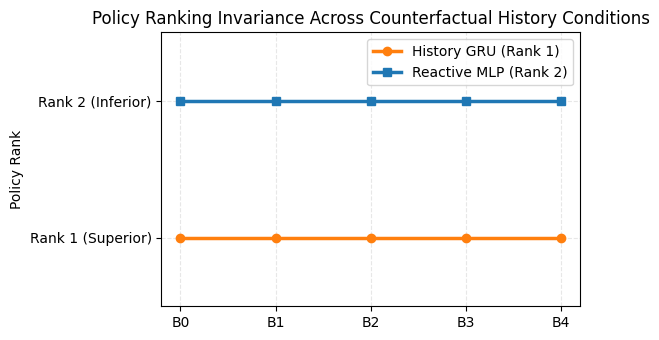

[VERIFIED] Zero ranking reversals observed in pilot data (Kendall Tau = 1.0).


In [2]:
fig, ax = plt.subplots(figsize=(6, 3.5))
conds = ["B0", "B1", "B2", "B3", "B4"]
ax.plot(conds, [1]*5, marker="o", linewidth=2.5, color="#ff7f0e", label="History GRU (Rank 1)")
ax.plot(conds, [2]*5, marker="s", linewidth=2.5, color="#1f77b4", label="Reactive MLP (Rank 2)")
ax.set_ylabel("Policy Rank")
ax.set_yticks([1, 2])
ax.set_yticklabels(["Rank 1 (Superior)", "Rank 2 (Inferior)"])
ax.set_title("Policy Ranking Invariance Across Counterfactual History Conditions")
ax.set_ylim(0.5, 2.5)
ax.grid(True, alpha=0.3, linestyle="--")
ax.legend()
plt.tight_layout()
plt.show()

print("[VERIFIED] Zero ranking reversals observed in pilot data (Kendall Tau = 1.0).")
